# 03 — Baseline Model
**IDX Exchange Data Science Internship — Predicting California Home Close Prices**

Author: Saanvi Prasad

This notebook covers **Week 4**:
- Train a **Linear Regression** as the first model
- Evaluate it using **R² on the test set**
- Record the baseline results
- **Deliverable:** this notebook

The "baseline" is the score that later models (Decision Tree, Random Forest, etc. in Week 5) need to beat.

## Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# >>> CHANGE THIS to the folder where your CSV files are (same as in 01 and 02) <<<
path = r"C:\Users\saanv\Desktop\idxexchange"

## 1. Load the train and test data from Week 3
These files were saved at the end of `02_preprocessing.ipynb`, so run that notebook first.
- **Train** = March 2025 – March 2026 (X = 13 months)
- **Test** = April 2026

In [2]:
train = pd.read_csv(os.path.join(path, "train_data.csv"))
test = pd.read_csv(os.path.join(path, "test_data.csv"))

print("Training rows:", len(train), "| months:", train["Month"].min(), "to", train["Month"].max())
print("Test rows:    ", len(test), "| month:", test["Month"].unique()[0])

Training rows: 140798 | months: 2025-03 to 2026-03
Test rows:     12465 | month: 2026-04


## 2. Prepare the data (same as Week 3)
This is the **same `prepare()` function** from `02_preprocessing.ipynb`. It fills missing values, takes logs, one-hot encodes County and City, and normalizes, all using the **training data only**.

In [3]:
number_cols = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet",
               "YearBuilt", "GarageSpaces", "Stories"]
flag_cols = ["LotSizeSquareFeet", "YearBuilt", "GarageSpaces", "Stories"]
yes_no_cols = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]


def prepare(train, test):
    train = train.copy()
    test = test.copy()

    # 1. Missing values
    for col in flag_cols:                          # flag first (before filling)
        train[col + "_missing"] = train[col].isna().astype(int)
        test[col + "_missing"] = test[col].isna().astype(int)
    for col in number_cols:                        # fill with TRAINING median
        median = train[col].median()
        train[col] = train[col].fillna(median)
        test[col] = test[col].fillna(median)
    for col in yes_no_cols:
        train[col] = train[col].fillna(0)
        test[col] = test[col].fillna(0)
    train["City"] = train["City"].fillna("Unknown")
    test["City"] = test["City"].fillna("Unknown")

    # 2. Log of skewed columns
    for d in [train, test]:
        d["LivingArea"] = np.log(d["LivingArea"])
        d["LotSizeSquareFeet"] = np.log(d["LotSizeSquareFeet"])

    # 3. Encoding: keep cities with 100+ training sales, the rest become "Other"
    city_counts = train["City"].value_counts()
    big_cities = city_counts[city_counts >= 100].index
    train["City"] = train["City"].where(train["City"].isin(big_cities), "Other")
    test["City"] = test["City"].where(test["City"].isin(big_cities), "Other")

    feature_cols = number_cols + [c + "_missing" for c in flag_cols] + yes_no_cols + ["CountyOrParish", "City"]
    X_train = pd.get_dummies(train[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = pd.get_dummies(test[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)   # same columns as train

    # 4. Normalize number columns with TRAINING mean and std
    for col in number_cols:
        mean = X_train[col].mean()
        std = X_train[col].std()
        X_train[col] = (X_train[col] - mean) / std
        X_test[col] = (X_test[col] - mean) / std

    y_train = np.log(train["ClosePrice"])
    y_test = np.log(test["ClosePrice"])
    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = prepare(train, test)
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

X_train: (140798, 397)
X_test:  (12465, 397)


## 3. Train the Linear Regression
The model learns one number (a **coefficient**) for each column. The prediction is the sum of each column × its coefficient, plus an intercept.

Remember the target is **log(price)**, so to get dollars back we use `np.exp()` on the predictions.

In [4]:
model = LinearRegression()
model.fit(X_train, y_train)

pred_log = model.predict(X_test)
pred_price = np.exp(pred_log)            # back to dollars
actual_price = np.exp(y_test)

print("Example predictions vs actual prices:")
pd.DataFrame({"actual": actual_price.values[:8], "predicted": pred_price[:8].round(0)})

Example predictions vs actual prices:


,actual,predicted
0,"449,000.00","408,448.00"
1,"1,286,500.00","2,143,951.00"
2,"2,937,592.00","1,727,230.00"
3,"1,199,900.00","1,335,406.00"
4,"860,000.00","901,178.00"
5,"1,328,000.00","1,066,833.00"
6,"1,040,000.00","1,235,979.00"
7,"1,020,000.00","1,327,749.00"


## 4. Evaluate on the test set
**R²** tells us how much of the variation in price the model explains:
- **1.0** = perfect predictions
- **0.0** = no better than just guessing the average price for every home

I calculate R² two ways:
- **R² in dollars**: the official metric
- **R² on log price**: rewards getting the *percentage* right, and isn't dominated by a few super-expensive homes

I also show the **MAE** (mean absolute error), the average number of dollars the prediction is off by.

In [5]:
r2_dollars = r2_score(actual_price, pred_price)
r2_log = r2_score(y_test, pred_log)
mae = mean_absolute_error(actual_price, pred_price)

print("Test R² (dollars):  ", round(r2_dollars, 4))
print("Test R² (log price):", round(r2_log, 4))
print("MAE: $", round(mae))

Test R² (dollars):   0.6764
Test R² (log price): 0.861
MAE: $ 266793


**What I notice:**
- The model explains about **68%** of the variation in April 2026 prices (R² ≈ 0.68). On the log scale it's even higher (≈ 0.86), so it gets the *percentage* right for most homes.
- The dollar R² is lower because a few very expensive homes ($10M+) have huge dollar errors, and R² in dollars weighs those heavily.
- On average the prediction is off by about **$267K** (MAE). That sounds like a lot, but the typical home here costs around $900K, and the average is pulled up by the expensive ones.

## 5. Compare with a simpler model
To see what the extra features add, I also train a Linear Regression using **only the 4 main features** (living area, bedrooms, bathrooms, lot size) on raw dollars, with no location and no log.

In [6]:
simple_cols = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet"]

train_simple = train[simple_cols].fillna(train[simple_cols].median())
test_simple = test[simple_cols].fillna(train[simple_cols].median())

simple_model = LinearRegression()
simple_model.fit(train_simple, train["ClosePrice"])
simple_pred = simple_model.predict(test_simple)

r2_simple = r2_score(test["ClosePrice"], simple_pred)
print("Simple model (4 features) test R²:", round(r2_simple, 4))
print("Full model test R²:               ", round(r2_dollars, 4))

Simple model (4 features) test R²: 0.4332
Full model test R²:                0.6764


Using only the 4 size features gives R² ≈ **0.43**. Adding location (county and city), the log transform, and the extra features raises it to ≈ **0.68**. **Location** makes the biggest difference: the same house costs very different amounts in different areas, which matches what we saw in Week 2.

## 6. Plots: how good are the predictions?

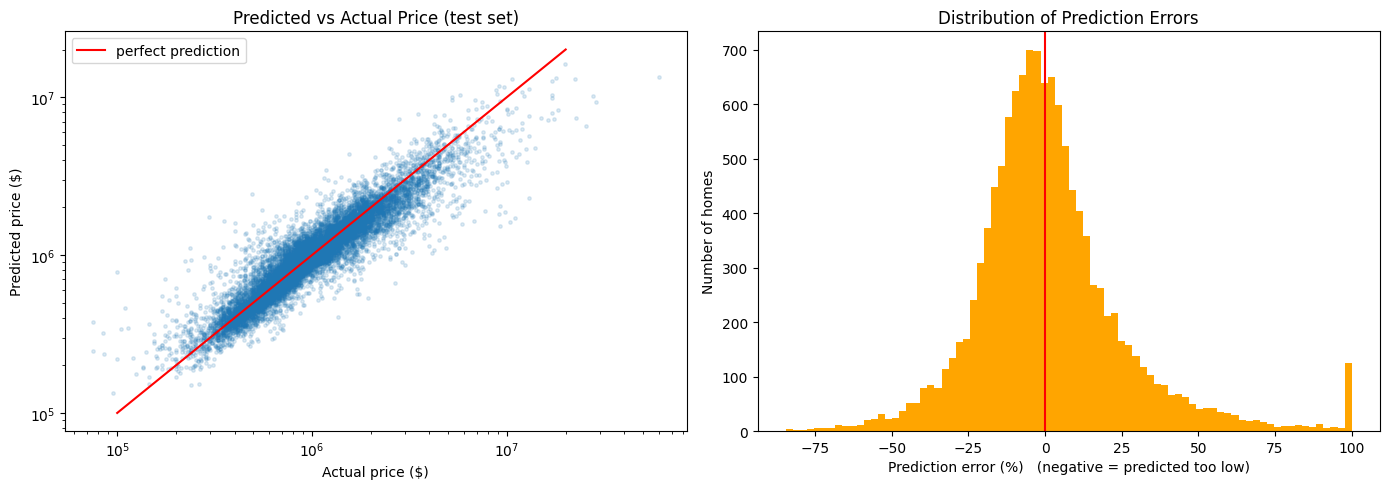

Homes predicted within 10% of the actual price: 42.9 %
Homes predicted within 20% of the actual price: 70.5 %


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: predicted vs actual (log scale so cheap and expensive homes both show up)
axes[0].scatter(actual_price, pred_price, alpha=0.15, s=6)
axes[0].plot([1e5, 2e7], [1e5, 2e7], color="red", label="perfect prediction")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Predicted vs Actual Price (test set)")
axes[0].legend()

# Right: percentage errors
pct_error = (pred_price - actual_price) / actual_price * 100
axes[1].hist(pct_error.clip(-100, 100), bins=80, color="orange")
axes[1].axvline(0, color="red")
axes[1].set_xlabel("Prediction error (%)   (negative = predicted too low)")
axes[1].set_ylabel("Number of homes")
axes[1].set_title("Distribution of Prediction Errors")

plt.tight_layout()
plt.show()

print("Homes predicted within 10% of the actual price:", round((abs(pct_error) <= 10).mean() * 100, 1), "%")
print("Homes predicted within 20% of the actual price:", round((abs(pct_error) <= 20).mean() * 100, 1), "%")

**What I notice:**
- The points follow the red "perfect prediction" line closely, for both cheap and expensive homes.
- Most errors are within about ±25%. About **43%** of homes are predicted within 10% of their real price, and about **70%** within 20%.
- The bar at the far right is homes the model over-predicted by 100% or more (errors bigger than 100% are grouped there). These are mostly low-priced sales, maybe fixer-uppers or unusual sales the model can't know about.

## 7. Which features matter most?
Because the number columns were standardized in Week 3, their coefficients can be compared to each other. A bigger (positive) coefficient means that feature raises the predicted price more.

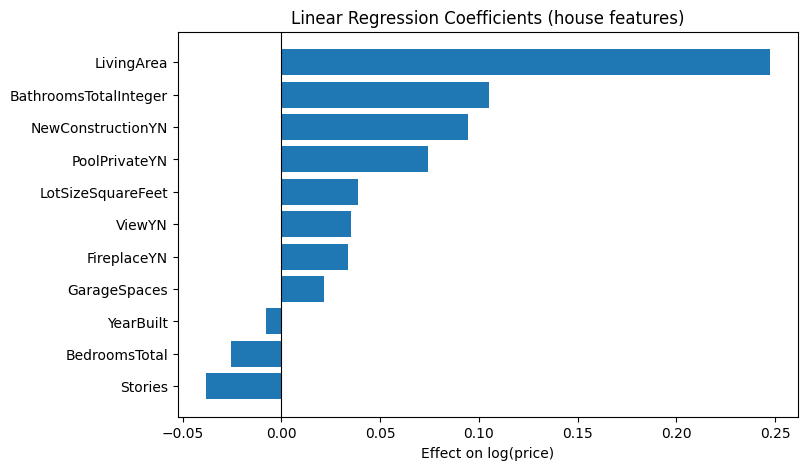

In [8]:
coefs = pd.Series(model.coef_, index=X_train.columns)
feature_coefs = coefs[number_cols + yes_no_cols].sort_values()

plt.figure(figsize=(8, 5))
plt.barh(feature_coefs.index, feature_coefs.values)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Linear Regression Coefficients (house features)")
plt.xlabel("Effect on log(price)")
plt.show()

**What I notice:**
- **Living area** has by far the biggest effect: bigger homes cost more.
- **Bathrooms**, **new construction**, and a **pool** also raise the price.
- **Bedrooms** has a small *negative* coefficient. That seems weird, but it's because bedrooms and living area are strongly related (Week 2). For the *same* living area, more bedrooms means smaller rooms, so it doesn't add value by itself.
- The county and city columns (not shown) also have big effects, since location matters a lot.

## 8. How much do the extreme prices affect R²?
R² in dollars is very sensitive to a few very expensive (or very cheap) homes. To see how much, I score **the same model** only on the April homes inside the middle 99% of prices, leaving out the **cheapest 0.5% and the most expensive 0.5%**. The 0.5% / 99.5% cutoffs come from the training data.

*My official baseline is still the R² on **all** April homes above. This is only to understand the errors.*

In [9]:
low = train["ClosePrice"].quantile(0.005)
high = train["ClosePrice"].quantile(0.995)
middle = (actual_price >= low) & (actual_price <= high)

r2_trimmed = r2_score(actual_price[middle], pred_price[middle])

print("Price cutoffs from training data: $", round(low), "to $", round(high))
print("Test homes kept:", middle.sum(), "of", len(middle))
print()
print("R² on ALL April homes (official):    ", round(r2_dollars, 4))
print("R² without top/bottom 0.5% of prices:", round(r2_trimmed, 4))

Price cutoffs from training data: $ 195000 to $ 8300450
Test homes kept: 12337 of 12465

R² on ALL April homes (official):     0.6764
R² without top/bottom 0.5% of prices: 0.7851


**What I notice:** when I leave out the cheapest and most expensive 0.5% of homes (128 of 12,465), R² goes from **0.68 to about 0.79**. So a small number of extreme homes cause a big part of the dollar error. The model works well for typical homes and struggles most with the very expensive ones, which is something better models in Week 5 could improve.

## 9. Record the baseline results

In [10]:
results = pd.DataFrame([
    {"model": "Linear Regression - 4 features, raw $", "test R2": round(r2_simple, 4)},
    {"model": "Linear Regression - all features, log price (BASELINE)", "test R2": round(r2_dollars, 4),
     "test R2 (log)": round(r2_log, 4), "MAE ($)": round(mae)},
    {"model": "Same baseline, scored without top/bottom 0.5% of prices",
     "test R2": round(r2_trimmed, 4)},
])
results["train months"] = "2025-03 to 2026-03 (X = 13)"
results["test month"] = "2026-04"

results.to_csv(os.path.join(path, "baseline_results.csv"), index=False)
print("Saved baseline_results.csv")
results

Saved baseline_results.csv


,model,test R2,test R2 (log),MAE ($),train months,test month
0,"Linear Regression - 4 features, raw $",0.43,NaN,NaN,2025-03 to 2026-03 (X = 13),2026-04
1,"Linear Regression - all features, log price (B...",0.68,0.86,"266,793.00",2025-03 to 2026-03 (X = 13),2026-04
2,"Same baseline, scored without top/bottom 0.5% ...",0.79,NaN,NaN,2025-03 to 2026-03 (X = 13),2026-04


---
## Summary
| | |
|---|---|
| Model | Linear Regression on log(ClosePrice) |
| Training data | March 2025 – March 2026 (X = 13 months) |
| Test data | April 2026 |
| **Test R² (baseline)** | **≈ 0.68** |
| Test R² on log price | ≈ 0.86 |
| Average error (MAE) | ≈ $267K |
| R² without the top/bottom 0.5% of prices | ≈ 0.79 |

**Takeaways:**
1. A simple Linear Regression already explains about two-thirds of the variation in home prices.
2. **Location** is the most important addition (R² goes from 0.43 to 0.68).
3. The biggest errors are on very expensive and very cheap homes.
4. Linear Regression assumes each feature adds the same amount everywhere (for example, a pool is worth the same % in every city), which isn't true in real life. Tree models in Week 5 might handle this better.

**Next (Week 5):** try Decision Tree and Random Forest models and compare their test R² to this baseline (≈ 0.68).